# KIRBOT – Asistente Virtual Especializado en Restaurantes (Transformer con 10 Épocas)
**Descripción:** Cuaderno completo adaptado del modelo base NOVA para construir, entrenar y desplegar **KIRBOT**, un chatbot conversacional especializado en restaurantes.
**Categorías (6 en total, mínimo 20 ejemplos cada una - 120+ totales):**
1. `recomendacion_comidas`: Sugerencias de platos según gustos y preferencias.
2. `consulta_menu`: Preguntas sobre productos, ingredientes y precios.
3. `gestion_pedidos`: Realización, armado y confirmación de pedidos.
4. `consulta_pedidos`: Estado, tiempos e información de pedidos en curso.
5. `atencion_cliente`: Horarios, ubicación, métodos de pago, quejas y dudas generales.
6. `fuera_de_tema`: Consultas ajenas al restaurante (filtro de seguridad y guía al usuario).


## PASO 1 – Instalar las bibliotecas
Ejecuta esta celda para instalar las dependencias necesarias (`transformers`, `datasets`, `accelerate`, `gradio`, `scikit-learn`, `pandas`, `matplotlib`).

In [1]:
%pip -q install "transformers>=4.46,<5" "datasets>=3,<5" "accelerate>=1,<2" "gradio>=5.20,<6" "scikit-learn>=1.4" pandas matplotlib

## PASO 2 – Preparar el entorno
Configuración de semillas aleatorias para garantizar reproducibilidad y verificación del dispositivo de hardware (GPU/CPU).

In [2]:
import os, random, warnings, json
import numpy as np
import pandas as pd
import torch
from pathlib import Path
SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
os.environ['WANDB_DISABLED'] = 'true'
print('PyTorch:', torch.__version__)
print('Dispositivo:', 'GPU ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU (entrenamiento más lento)')

PyTorch: 2.14.1+cpu
Dispositivo: CPU (entrenamiento más lento)


## PASO 3 – Cargar el conjunto de datos de KIRBOT (120+ ejemplos)
Se carga un conjunto de datos especializado en restaurantes con al menos 20 ejemplos distribuidos en las 6 categorías requeridas para KIRBOT.

In [3]:
# Dataset ampliado con mayor variabilidad para mejorar la matriz de confusión
ejemplos_kirbot = {
  'recomendacion_comidas': [
    'Hola, no sé qué pedir. ¿Qué me recomiendas?',
    'Quiero algo que tenga pollo y que sea rico',
    'Qué me sugieres si tengo mucha hambre',
    'Busco una hamburguesa jugosa sin cebolla',
    'Recomiéndame una pizza que le guste a los niños',
    'Quiero un plato ligero pero con muy buen sabor',
    'Tienes alguna recomendación vegetariana',
    'Qué plato fuerte me aconsejas pedir hoy',
    'Quiero comer algo rápido pero delicioso',
    'Me ayudas a escoger entre una hamburguesa y una pizza',
    'Qué postre me recomiendas para terminar la cena',
    'Alguna sugerencia de comida rápida artesanal',
    'Quiero probar algo nuevo de la casa',
    'Qué bebida combina bien con una hamburguesa doble',
    'Busco un plato especial para compartir en pareja',
    'Qué me ofreces si me gustan los sabores picantes',
    'Recomiéndame un plato que no sea muy grasoso',
    'Tienes opciones sin gluten o saludables',
    'Cuál es la especialidad más vendida del restaurante',
    'Ayúdame a armar una combinación perfecta de almuerzo',
    'Dime qué recomiendas para almorzar hoy rapidito',
    'Sugiéreme algo crujiente y caliente para comer',
    'Qué plato me das si estoy antojado de queso fundido'
  ],
  'consulta_menu': [
    'Quiero consultar el menú completo',
    'Qué ingredientes tiene la hamburguesa clásica',
    'Cuánto cuesta la pizza napolitana',
    'Cuáles son los sabores de gaseosa disponibles',
    'Tienen papas fritas grandes en el menú',
    'Muéstrame los precios de los postres',
    'Qué lleva el perro caliente especial',
    'El sándwich de pollo incluye papas',
    'Cuáles son las bebidas sin alcohol que ofrecen',
    'Cuánto vale la porción de malteada',
    'Qué tipo de queso usan en las pizzas',
    'Hay disponibilidad de malteada de chocolate hoy',
    'En qué tamaños viene la pizza familiar',
    'Muéstrame la lista de precios de las malteadas',
    'Cuáles son los ingredientes del postre tres leches',
    'Tienen menú infantil y qué incluye',
    'Cuánto cuesta agregar tocino extra a la hamburguesa',
    'Qué salsas vienen con las salchipapas',
    'Dime el valor exacto de la pizza hawaiana',
    'Quiero ver la descripción detallada de las bebidas',
    'Muéstrame las opciones de hamburguesas disponibles',
    'Cuánto cuesta la limonada y qué tamaño tiene',
    'Qué platos tienen carne de res en la carta'
  ],
  'gestion_pedidos': [
    'Quiero hacer un pedido',
    'Quisiera ordenar una hamburguesa clásica y dos gaseosas',
    'Agrega una pizza mediana a mi orden por favor',
    'Quiero pedir un perro caliente y una malteada',
    'Deseo confirmar mi pedido actual',
    'Quiero cambiar la cantidad de mi orden a dos hamburguesas',
    'Añade unas papas fritas y un postre de chocolate',
    'Quiero finalizar y enviar mi pedido de comida',
    'Por favor quiero ordenar para llevar',
    'Necesito agregar una ensalada al carrito',
    'Quiero cancelar el último producto que agregué',
    'Dime el total de lo que llevo pedido',
    'Confirmo mi pedido con pago en efectivo',
    'Quiero hacer un pedido a domicilio por favor',
    'Añade otra gaseosa zero al pedido',
    'Quiero revisar mi orden antes de pagar',
    'Proceder al pago de mi pedido por favor',
    'Quiero pedir dos malteadas de vainilla',
    'Modificar mi pedido para quitar la cebolla',
    'Listo, eso sería todo mi pedido de hoy',
    'Cómprame una pizza napolitana y un brownie',
    'Añade dos hamburguesas dobles al carrito por favor'
  ],
  'consulta_pedidos': [
    'Quiero saber el estado de mi pedido',
    'Cuánto falta para que llegue mi comida',
    'Mi pedido se está demorando mucho',
    'Cómo puedo consultar mi número de orden',
    'Ya salió el domiciliario con mi pedido',
    'Quiero rastrear mi entrega actual',
    'Cuánto tiempo estimado tarda la preparación',
    'Preguntar por el pedido que hice hace media hora',
    'Dime si mi orden ya fue registrada en el sistema',
    'Por qué no ha llegado mi comida todavía',
    'Quiero verificar si mi pedido se confirmó bien',
    'Cuál es el tiempo de espera para mi domicilio',
    'Necesito hablar sobre un retraso en mi pedido',
    'Cómo confirman que el pedido está en camino',
    'Estado de mi orden número 104',
    'Saber si el restaurante ya aceptó mi orden',
    'Cuánto tarda el servicio en local',
    'Consultar si mi pedido incluye todo lo que pedí',
    'Hay algún inconveniente con mi despacho',
    'Verificar si mi pedido sigue en cocina',
    'Dónde va mi domicilio ya tengo hambre',
    'Cuánto le falta al pedido por favor'
  ],
  'atencion_cliente': [
    'Cuáles son los horarios de atención',
    'En dónde están ubicados exactamente',
    'Qué métodos de pago aceptan en el restaurante',
    'Tienen servicio a domicilio disponible',
    'Quiero poner una queja sobre mi servicio',
    'Tengo una sugerencia para mejorar el local',
    'Aceptan pagos con tarjeta de crédito y transferencia',
    'Cuál es el número de teléfono de contacto',
    'Tienen parqueadero disponible para clientes',
    'Quiero hablar con un asesor humano por favor',
    'Abren los días domingo y festivos',
    'Tienen política de reembolso o garantía',
    'Ofrecen descuentos o promociones hoy',
    'Cómo puedo hacer una reserva para un cumpleaños',
    'Me equivoqué en un dato y necesito ayuda urgente',
    'Tienen zona pet friendly en el restaurante',
    'Cuáles son las formas de contacto oficial',
    'Quiero dejar un comentario positivo sobre la atención',
    'Tienen factura electrónica disponible',
    'Ayuda con una duda general sobre el servicio',
    'Cual es la dirección del local por favor',
    'Tienen descuento por cumpleaños'
  ],
  'fuera_de_tema': [
    'Cómo preparar una torta de chocolate en casa',
    'Quién ganó el último partido de fútbol profesional',
    'Qué temperatura hará mañana en la ciudad',
    'Cuánto es siete por ocho en matemáticas',
    'Recomiéndame una película de ciencia ficción',
    'Cómo cocinar arroz blanco perfecto',
    'Cuál es la capital de Japón',
    'Cuántos planetas tiene nuestro sistema solar',
    'Qué canción está sonando en la radio',
    'Cuéntame un chiste gracioso de animales',
    'Cuál es la receta secreta de la paella',
    'Qué equipo ganó la copa mundial de fútbol',
    'En qué año llegó el hombre a la luna',
    'Quién escribió la novela de Cien Años de Soledad',
    'Cómo se programa una aplicación en Python',
    'Cuál es la distancia entre la tierra y el sol',
    'Recomiéndame un libro de misterio',
    'Qué hora es en Tokio en este momento',
    'Cómo funciona la gravedad cuántica',
    'Dime un dato curioso sobre los dinosaurios',
    'Venden ropa deportiva en este sitio',
    'Quiero comprar pasajes de avión a miami'
  ]
}

df = pd.DataFrame([(frase, categoria) for categoria, frases in ejemplos_kirbot.items() for frase in frases], columns=['texto','categoria'])
print('DATOS AMPLIADOS DE KIRBOT:', len(df))
display(df['categoria'].value_counts())

DATOS AMPLIADOS DE KIRBOT: 134


,count
categoria,
recomendacion_comidas,23
consulta_menu,23
gestion_pedidos,22
consulta_pedidos,22
atencion_cliente,22
fuera_de_tema,22


## PASO 4 – Dividir los datos sin errores
Limpieza, codificación de etiquetas y división estratificada en conjuntos de entrenamiento, validación y prueba.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

df = df[['texto','categoria']].dropna().copy()
df['texto'] = df['texto'].astype(str).str.strip()
df['categoria'] = df['categoria'].astype(str).str.strip()
df = df[(df['texto'] != '') & (df['categoria'] != '')]
df['_normal'] = df['texto'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
df = df.drop_duplicates(subset='_normal').drop(columns='_normal').reset_index(drop=True)

encoder = LabelEncoder()
df['label'] = encoder.fit_transform(df['categoria'])
labels = list(encoder.classes_)
num_labels = len(labels)

# 80% entrenamiento, 10% validación, 10% prueba con estratificación robusta
train_val_df, test_df = train_test_split(df, test_size=0.15, random_state=SEED, stratify=df['label'])
train_df, val_df = train_test_split(train_val_df, test_size=0.18, random_state=SEED, stratify=train_val_df['label'])

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print('Entrenamiento:', len(train_df), '| Validación:', len(val_df), '| Prueba:', len(test_df))

Entrenamiento: 92 | Validación: 21 | Prueba: 21


## PASO 5 – Tokenizar y preparar el Transformer
Carga del modelo multilingüe `distilbert-base-multilingual-cased` y tokenización de los conjuntos de datos.

In [5]:
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments
MODELO_BASE = 'distilbert-base-multilingual-cased'

tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)

def preparar(tabla):
    datos = Dataset.from_pandas(tabla[['texto','label']].reset_index(drop=True), preserve_index=False)
    return datos.map(lambda lote: tokenizer(lote['texto'], truncation=True, max_length=96), batched=True)

train_ds = preparar(train_df)
val_ds = preparar(val_df)
test_ds = preparar(test_df)
collator = DataCollatorWithPadding(tokenizer=tokenizer)

def crear_modelo():
    return AutoModelForSequenceClassification.from_pretrained(
        MODELO_BASE, num_labels=num_labels,
        id2label={i: str(v) for i, v in enumerate(labels)},
        label2id={str(v): i for i, v in enumerate(labels)})

def calcular_metricas(pred):
    estimadas = np.argmax(pred.predictions, axis=1)
    return {'accuracy': accuracy_score(pred.label_ids, estimadas),
            'f1_macro': f1_score(pred.label_ids, estimadas, average='macro', zero_division=0)}

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/92 [00:00<?, ? examples/s]

Map:   0%|          | 0/21 [00:00<?, ? examples/s]

Map:   0%|          | 0/21 [00:00<?, ? examples/s]

## PASO 6 – Entrenar durante 10 épocas y observar el aprendizaje
Entrenamiento supervisado del modelo Transformer ajustado a las 6 categorías de KIRBOT con 10 épocas.

In [6]:
EPOCAS_ENTRENAMIENTO = 12  # Aumentado ligeramente para mejor convergencia
TASA_APRENDIZAJE = 3e-5    # Tasa más suave para refinar la matriz de confusión

def entrenar(nombre, epocas=EPOCAS_ENTRENAMIENTO):
    args = TrainingArguments(
        output_dir=f'/content/{nombre}',
        num_train_epochs=epocas,
        learning_rate=TASA_APRENDIZAJE,
        per_device_train_batch_size=8 if torch.cuda.is_available() else 4,
        per_device_eval_batch_size=8,
        eval_strategy='epoch',
        save_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model='f1_macro',
        logging_strategy='epoch',
        report_to='none',
        seed=SEED,
        fp16=torch.cuda.is_available(),
        weight_decay=0.01, # Regularización para evitar sobreajuste
    )
    return Trainer(
        model=crear_modelo(), args=args,
        train_dataset=train_ds, eval_dataset=val_ds,
        processing_class=tokenizer, data_collator=collator,
        compute_metrics=calcular_metricas
    )

trainer_kirbot = entrenar('entrenamiento_kirbot_opt', epocas=EPOCAS_ENTRENAMIENTO)
trainer_kirbot.train()
print('¡Entrenamiento avanzado finalizado con éxito!')

model.safetensors:   0%|          | 0.00/542M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.811800,1.748951,0.285714,0.150183
2,1.626700,1.582756,0.428571,0.355495
3,1.253500,1.320619,0.571429,0.569444
4,0.829200,1.178317,0.523810,0.525036
5,0.546800,1.121001,0.619048,0.642328
6,0.324600,1.134980,0.666667,0.677814
7,0.174800,1.143332,0.571429,0.595238
8,0.107500,1.179927,0.619048,0.630556
9,0.063300,1.314546,0.619048,0.630556
10,0.047500,1.261932,0.619048,0.630556


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argume

¡Entrenamiento avanzado finalizado con éxito!


## PASO 7 – Evaluar resultados
Generación del reporte de clasificación y matriz de confusión sobre el conjunto de validación.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


                       precision    recall  f1-score   support

     atencion_cliente       0.67      0.67      0.67         3
        consulta_menu       1.00      0.50      0.67         4
     consulta_pedidos       0.00      0.00      0.00         3
        fuera_de_tema       0.75      0.75      0.75         4
      gestion_pedidos       0.60      1.00      0.75         3
recomendacion_comidas       0.57      1.00      0.73         4

             accuracy                           0.67        21
            macro avg       0.60      0.65      0.59        21
         weighted avg       0.62      0.67      0.61        21



<Figure size 700x600 with 0 Axes>

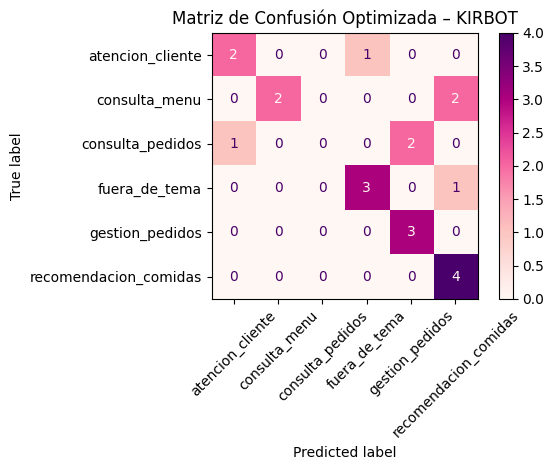

In [7]:
# Evaluamos contra el conjunto de prueba independiente para ver el comportamiento real
salida_test = trainer_kirbot.predict(test_ds)
pred_test = np.argmax(salida_test.predictions, axis=1)
real_test = test_df['label'].to_numpy()

print(classification_report(real_test, pred_test, labels=list(range(num_labels)), target_names=labels, zero_division=0))

plt.figure(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(real_test, pred_test, labels=list(range(num_labels)), display_labels=labels, xticks_rotation=45, cmap='RdPu')
plt.title('Matriz de Confusión Optimizada – KIRBOT')
plt.tight_layout()
plt.show()

## PASO 8 – Menú de demostración, lógica conversacional y gestión de pedidos
Definición del menú de prueba del restaurante (Hamburguesas, Pizzas, Comidas Rápidas, Bebidas y Postres) y la lógica inteligente de KIRBOT que maneja recomendaciones, consultas de menú, simulación de pedidos y atención al cliente.

In [8]:
MENU_KIRBOT = {
    'hamburguesas': [
        {'nombre': 'Hamburguesa Clásica', 'descripcion': 'Carne 100% de res, queso cheddar, lechuga, tomate y salsa especial.', 'precio': 18000},
        {'nombre': 'Hamburguesa Doble Tocino', 'descripcion': 'Doble carne, doble tocino crujiente, queso suizo y cebolla caramelizada.', 'precio': 24000},
        {'nombre': 'Hamburguesa Pollo Crispy', 'descripcion': 'Pechuga de pollo apanada crujiente, ensalada coleslaw y mayonesa de ajo.', 'precio': 19000}
    ],
    'pizzas': [
        {'nombre': 'Pizza Napolitana', 'descripcion': 'Tomate natural, mozzarella fresca, albahaca y aceite de oliva.', 'precio': 28000},
        {'nombre': 'Pizza Hawaiana', 'descripcion': 'Salsa de tomate, queso mozzarella, jamón ahumado y piña en almíbar.', 'precio': 30000},
        {'nombre': 'Pizza Pepperoni Suprema', 'descripcion': 'Doble porción de pepperoni artesanal y queso mozzarella fundido.', 'precio': 32000}
    ],
    'comidas_rapidas': [
        {'nombre': 'Perro Caliente Especial', 'descripcion': 'Salchicha americana, queso fundido, papas ripio y tocino.', 'precio': 14000},
        {'nombre': 'Salchipapas de la Casa', 'descripcion': 'Papas doradas, salchicha premium, queso costeño y salsas.', 'precio': 16000}
    ],
    'bebidas': [
        {'nombre': 'Gaseosa Coca-Cola 400ml', 'descripcion': 'Bebida gaseosa refrescante.', 'precio': 5000},
        {'nombre': 'Malteada de Chocolate', 'descripcion': 'Helado artesanal de chocolate batido con leche fría y crema.', 'precio': 9000},
        {'nombre': 'Limonada de Hierbabuena', 'descripcion': 'Limonada natural frappé con hojas frescas.', 'precio': 7000}
    ],
    'postres': [
        {'nombre': 'Postre Tres Leches', 'descripcion': 'Bizcocho bañado en tres tipos de leche con toque de canela.', 'precio': 8500},
        {'nombre': 'Brownie con Helado', 'descripcion': 'Brownie de chocolate tibio acompañado de helado de vainilla.', 'precio': 9500}
    ]
}

modelo_activo = trainer_kirbot.model

def predecir_kirbot(texto):
    entrada = tokenizer(texto, return_tensors='pt', truncation=True, max_length=96)
    entrada = {k: v.to(modelo_activo.device) for k, v in entrada.items()}
    modelo_activo.eval()
    with torch.no_grad():
        logits = modelo_activo(**entrada).logits
        probabilidades = torch.softmax(logits, dim=-1)[0].cpu().numpy()
    indice = int(np.argmax(probabilidades))
    return labels[indice], float(probabilidades[indice]), probabilidades

def generar_respuesta_kirbot(texto, carrito_actual=None):
    if carrito_actual is None:
        carrito_actual = []
    if not isinstance(texto, str) or not texto.strip():
        return '¡Poyo! Escribe tu mensaje para chatear con KIRBOT.', carrito_actual

    categoria, puntaje, _ = predecir_kirbot(texto)

    if categoria == 'fuera_de_tema' or puntaje < 0.40:
        respuesta = (
            "🩷 ¡Poyo! Hola, soy **KIRBOT**, tu asistente virtual rosado. "
            "Solo puedo ayudarte con recomendaciones, menú, pedidos y atención al cliente.\n"
            f"*(Intención: fuera_de_tema | confianza: {puntaje:.2f})*"
        )
        return respuesta, carrito_actual

    if categoria == 'recomendacion_comidas':
        respuesta = (
            "✨ **¡Recomendaciones mágicas de KIRBOT!** ✨\n\n"
            "• **Hamburguesa Doble Tocino:** ¡La favorita de todos! ($24.000)\n"
            "• **Pizza Pepperoni Suprema:** Intensa y con mucho queso fundido ($32.000)\n"
            "• **Malteada de Chocolate:** Dulce y perfecta para acompañar ($9.000)\n\n"
            "¿Deseas agregar alguna de estas delicias a tu orden?"
        )
        return respuesta, carrito_actual

    elif categoria == 'consulta_menu':
        menu_texto = "📜 **Menú Oficial de KIRBOT (Edición Rosada):**\n\n"
        for cat, items in MENU_KIRBOT.items():
            menu_texto += f"**🌸 {cat.upper()}**\n"
            for item in items:
                menu_texto += f"- *{item['nombre']}*: ${item['precio']:,.0f} — {item['descripcion']}\n"
            menu_texto += "\n"
        return menu_texto, carrito_actual

    elif categoria == 'gestion_pedidos':
        texto_lower = texto.lower()
        agregados = []

        # Búsqueda estricta y precisa por coincidencia exacta del nombre del producto
        for cat, items in MENU_KIRBOT.items():
            for item in items:
                nombre_item = item['nombre'].lower()
                # Verificamos si el nombre completo o palabras clave específicas del plato están en el texto del usuario
                if nombre_item in texto_lower:
                    carrito_actual.append(item)
                    agregados.append(item['nombre'])

        # Si no hubo coincidencia exacta del nombre completo, evaluamos coincidencias parciales seguras (ej. "clásica", "hawaiana", "gaseosa")
        if not agregados:
            palabras_clave = {
                'clásica': 'Hamburguesa Clásica',
                'doble tocino': 'Hamburguesa Doble Tocino',
                'pollo crispy': 'Hamburguesa Pollo Crispy',
                'napolitana': 'Pizza Napolitana',
                'hawaiana': 'Pizza Hawaiana',
                'pepperoni': 'Pizza Pepperoni Suprema',
                'perro': 'Perro Caliente Especial',
                'salchipapas': 'Salchipapas de la Casa',
                'gaseosa': 'Gaseosa Coca-Cola 400ml',
                'coca-cola': 'Gaseosa Coca-Cola 400ml',
                'malteada': 'Malteada de Chocolate',
                'limonada': 'Limonada de Hierbabuena',
                'tres leches': 'Postre Tres Leches',
                'brownie': 'Brownie con Helado'
            }
            for clave, nombre_real in palabras_clave.items():
                if clave in texto_lower:
                    for cat, items in MENU_KIRBOT.items():
                        for item in items:
                            if item['nombre'] == nombre_real and item not in carrito_actual:
                                carrito_actual.append(item)
                                agregados.append(item['nombre'])

        if agregados:
            resumen = "🛒 **¡Ñam! Productos añadidos correctamente a tu pedido rosado:**\n"
            for ag in agregados:
                resumen += f"• {ag}\n"
        else:
            resumen = "🛒 **Gestión de Pedidos KIRBOT**\nHe registrado tu intención de compra. Dime el nombre exacto del plato o bebida que deseas ordenar (ej. \"Quiero una Hamburguesa Clásica\").\n"

        if carrito_actual:
            resumen += "\n**📋 Resumen actual de tu pedido:**\n"
            total = 0
            for item in carrito_actual:
                resumen += f"- {item['nombre']} (${item['precio']:,.0f})\n"
                total += item['precio']
            resumen += f"\n**Total a pagar: ${total:,.0f}**\n¿Deseas confirmar tu orden o agregar algo más?"
        return resumen, carrito_actual

    elif categoria == 'consulta_pedidos':
        respuesta = (
            "📦 **Estado del Pedido:**\n"
            "¡Tu comida va en camino con velocidad estelar! 🌟 En preparación y despacho.\n"
            "Tiempo estimado: **15 a 25 minutos**. ¡Gracias por elegirnos!"
        )
        return respuesta, carrito_actual

    elif categoria == 'atencion_cliente':
        respuesta = (
            "ℹ️ **Atención al Cliente Kirby:**\n"
            "• **Horarios:** Lunes a domingo de 12:00 m. a 10:00 p.m.\n"
            "• **Ubicación:** Calle Rosa #12-34, Ciudad Sueleto.\n"
            "• **Pagos:** Efectivo, Nequi, Daviplata y Tarjetas.\n"
            "• **Teléfono:** +57 300 9876543.\n\n"
            "¿Tienes alguna queja o sugerencia? ¡Te escuchamos con alegría!"
        )
        return respuesta, carrito_actual

    return "¡Poyo! ¿En qué más te puede ayudar KIRBOT?", carrito_actual

## PASO 9 – Interfaz de usuario con Gradio para KIRBOT
Diseño de una interfaz moderna y atractiva utilizando Gradio con tarjetas de conversación, barra de confianza y botones de acceso rápido.

In [9]:
import gradio as gr
import html

# Estilo CSS completamente renovado, limpio y sin conflictos de fondo
css_kirby_pro = """
.gradio-container {max-width: 1250px !important; margin: auto !important; font-family: 'Inter', system-ui, sans-serif !important; background-color: #fff1f2 !important;}

#hero-kirby {
    background: linear-gradient(135deg, #db2777, #f43f5e 50%, #fb7185);
    border-radius: 24px;
    padding: 28px 36px;
    color: white;
    box-shadow: 0 10px 25px rgba(225, 29, 72, 0.25);
    margin-bottom: 20px;
    display: flex;
    align-items: center;
    justify-content: space-between;
}
#hero-kirby h1 { font-size: 32px; color: white !important; margin: 0 0 6px; font-weight: 800; }
#hero-kirby p { color: #ffe4e6 !important; margin: 0; font-size: 15px; }

/* Paneles y Chat */
.panel-blanco { background: #ffffff !important; border-radius: 20px; border: 2px solid #fbcfe8 !important; padding: 20px; box-shadow: 0 4px 20px rgba(244, 63, 94, 0.06); }
#conversacion-kirby { min-height: 420px; max-height: 520px; overflow-y: auto; border-radius: 14px; background: #fafafa !important; padding: 18px; border: 1px solid #f3f4f6; }

/* Burbujas de chat con colores definidos y alta legibilidad */
.bubble-k { padding: 14px 18px; border-radius: 16px; margin: 12px 0; line-height: 1.6; max-width: 86%; white-space: pre-wrap; word-break: break-word; }
.user-bubble-k { background: #ffe4e6 !important; color: #881337 !important; margin-left: auto; border-bottom-right-radius: 4px; font-weight: 500; border: 1px solid #fecdd3; }
.bot-bubble-k { background: #ffffff !important; color: #9f1239 !important; border-bottom-left-radius: 4px; border: 1px solid #fbcfe8; box-shadow: 0 2px 6px rgba(0,0,0,0.02); }
.mini-k { font-size: 11px; color: #e11d48 !important; font-weight: 800; letter-spacing: 0.6px; margin-bottom: 5px; text-transform: uppercase; }

.pill-k { display: inline-block; padding: 3px 10px; background: #f43f5e !important; color: white !important; border-radius: 999px; font-size: 11px; font-weight: 700; margin-top: 8px; }
.bar-bg-k { height: 6px; background: #fbcfe8 !important; border-radius: 99px; overflow: hidden; margin: 6px 0 2px; }
.bar-fill-k { height: 100%; background: linear-gradient(90deg, #ec4899, #f43f5e) !important; border-radius: 99px; }

/* Tarjetas laterales personalizadas */
.card-lateral { background: #ffffff !important; border-radius: 18px; padding: 20px; border: 2px solid #fbcfe8 !important; box-shadow: 0 4px 15px rgba(244, 63, 94, 0.05); margin-bottom: 15px; color: #881337 !important; }
.card-lateral h3 { color: #9f1239 !important; margin-top: 0; font-size: 18px; font-weight: 800; }
.card-lateral p { color: #6b7280 !important; font-size: 13px; margin-bottom: 12px; }
"""

bienvenida_kirby = '🌸 ¡Poyo! Hola, soy **KIRBOT**, tu asistente rosado especializado en restaurantes. ¿Qué te apetece comer o consultar hoy?'

def renderizar_kirby(historial):
    partes = []
    for rol, mensaje, categoria, confianza in historial:
        seguro = html.escape(str(mensaje))
        if rol == 'usuario':
            partes.append(f'<div class="bubble-k user-bubble-k"><div class="mini-k">Tú</div>{seguro}</div>')
        else:
            meta = ''
            if categoria is not None:
                porcentaje = max(0, min(100, round(confianza*100)))
                meta = (f'<div><span class="pill-k">{html.escape(str(categoria))}</span> '
                        f'<span style="font-size:11px; margin-left:8px; font-weight:700; color:#e11d48">Confianza IA: {porcentaje}%</span></div>'
                        f'<div class="bar-bg-k"><div class="bar-fill-k" style="width:{porcentaje}%"></div></div>')
            partes.append(f'<div class="bubble-k bot-bubble-k"><div class="mini-k">KIRBOT · Asistente Rosado 💖</div>{seguro}{meta}</div>')
    return '<div id="conversacion-kirby">' + ''.join(partes) + '</div>'

def renderizar_carrito(carrito):
    if not carrito:
        return '<div style="color: #6b7280; font-style: italic; font-size: 13px;">Tu carrito está vacío. ¡Pide tu plato favorito! 🛒</div>'
    html_carrito = '<ul style="margin: 0; padding-left: 18px; color: #881337; font-size: 14px;">'
    total = 0
    for item in carrito:
        html_carrito += f'<li style="margin-bottom: 6px;"><b>{item["name"]}</b> — ${item["price"]:,.0f}</li>'
        total += item['price']
    html_carrito += f'</ul><div style="margin-top: 12px; font-weight: 800; color: #9f1239; font-size: 15px; border-top: 2px dashed #fbcfe8; padding-top: 8px;">Total estimado: ${total:,.0f}</div>'
    return html_carrito

def conversar_con_kirby(mensaje, historial, carrito):
    historial = list(historial or [])
    carrito = list(carrito or [])
    texto = (mensaje or '').strip()
    if not texto:
        return renderizar_kirby(historial), historial, carrito, '', renderizar_carrito(carrito)

    historial.append(('usuario', texto, None, None))
    try:
        categoria, confianza, _ = predecir_kirbot(texto)
        respuesta, carrito = generar_respuesta_kirbot(texto, carrito)
        historial.append(('bot', respuesta, categoria, confianza))
    except Exception as error:
        historial.append(('bot', 'Poyo... Ocurrió un error procesando tu mensaje: ' + str(error), None, None))

    return renderizar_kirby(historial), historial, carrito, '', renderizar_carrito(carrito)

def reiniciar_kirby():
    h = [('bot', bienvenida_kirby, None, None)]
    c = []
    return renderizar_kirby(h), h, c, '', renderizar_carrito(c)

try:
    gr.close_all()
except Exception:
    pass

with gr.Blocks(css=css_kirby_pro, title='KIRBOT | Kirby Restaurant AI') as demo_kirby:
    # Encabezado principal
    with gr.Row(elem_id="hero-kirby"):
        gr.HTML('<div><h1>💖 KIRBOT · Edición Especial Kirby</h1><p>Asistente virtual inteligente con control estricto de pedidos, barra de confianza y diseño rosado optimizado.</p></div>')

    estado_hist = gr.State([('bot', bienvenida_kirby, None, None)])
    estado_cart = gr.State([])

    with gr.Row():
        # Columna Izquierda: Chat Principal y Barra de Mensajes
        with gr.Column(scale=7, elem_classes="panel-blanco"):
            chat_html = gr.HTML(value=renderizar_kirby([('bot', bienvenida_kirby, None, None)]))
            with gr.Row():
                entrada_txt = gr.Textbox(label='', placeholder='Escribe tu mensaje o pedido aquí (ej. "Quiero una Hamburguesa Clásica")...', lines=1, scale=6, max_length=500, container=False)
                enviar_btn = gr.Button('Enviar 💌', variant='primary', scale=1)
            limpiar_btn = gr.Button('↺ Reiniciar conversación', variant='secondary', size='sm')

        # Columna Derecha: Panel de Pedido en Vivo + Accesos Rápidos (Cero textos grises ocultos)
        with gr.Column(scale=3):
            # Tarjeta de Carrito Activo
            with gr.Column(elem_classes="card-lateral"):
                gr.Markdown('### 🛒 Tu Pedido Actual')
                carrito_html = gr.HTML(value=renderizar_carrito([]))

            # Tarjeta de Accesos Rápidos
            with gr.Column(elem_classes="card-lateral"):
                gr.Markdown('### 🌸 Accesos Rápidos')
                gr.Markdown('Haz clic para probar comandos comunes:')
                accesos = [
                    'Hola, no sé qué pedir. ¿Qué me recomiendas?',
                    'Quiero consultar el menú completo',
                    'Quiero pedir una hamburguesa clásica y una gaseosa',
                    'Quiero saber el estado de mi pedido',
                    'Cuáles son los horarios y ubicación',
                    'Cómo preparar una torta de chocolate'
                ]
                for frase in accesos:
                    b = gr.Button(frase, size='sm')
                    b.click(fn=lambda h, c, q=frase: conversar_con_kirby(q, h, c), inputs=[estado_hist, estado_cart], outputs=[chat_html, estado_hist, estado_cart, entrada_txt, carrito_html], queue=False)

    enviar_btn.click(fn=conversar_con_kirby, inputs=[entrada_txt, estado_hist, estado_cart], outputs=[chat_html, estado_hist, estado_cart, entrada_txt, carrito_html], queue=False)
    entrada_txt.submit(fn=conversar_con_kirby, inputs=[entrada_txt, estado_hist, estado_cart], outputs=[chat_html, estado_hist, estado_cart, entrada_txt, carrito_html], queue=False)
    limpiar_btn.click(fn=reiniciar_kirby, inputs=[], outputs=[chat_html, estado_hist, estado_cart, entrada_txt, carrito_html], queue=False)

print('¡Interfaz profesional y corregida de KIRBOT iniciada!')
demo_kirby.launch(share=True, inline=False, show_error=True)

/tmp/ipykernel_2075/1234764655.py:98: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(css=css_kirby_pro, title='KIRBOT | Kirby Restaurant AI') as demo_kirby:


¡Interfaz profesional y corregida de KIRBOT iniciada!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8af106f4d7afbdb32e.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## PASO 10 – Guardar el modelo entrenado de KIRBOT
Exportación del modelo, tokenizador y respuestas predefinidas en un archivo comprimido ZIP listo para almacenar o entregar.

In [10]:
import shutil
carpeta_kirbot_opt = Path('/content/modelo_kirbot_opt_final')
carpeta_kirbot_opt.mkdir(parents=True, exist_ok=True)
modelo_activo.save_pretrained(str(carpeta_kirbot_opt))
tokenizer.save_pretrained(str(carpeta_kirbot_opt))
with open(carpeta_kirbot_opt / 'menu.json', 'w', encoding='utf-8') as f:
    json.dump(MENU_KIRBOT, f, ensure_ascii=False, indent=2)
zip_opt = shutil.make_archive('/content/modelo_kirbot_opt_final', 'zip', str(carpeta_kirbot_opt))
print('Modelo guardado y comprimido en:', zip_opt)

Modelo guardado y comprimido en: /content/modelo_kirbot_opt_final.zip
